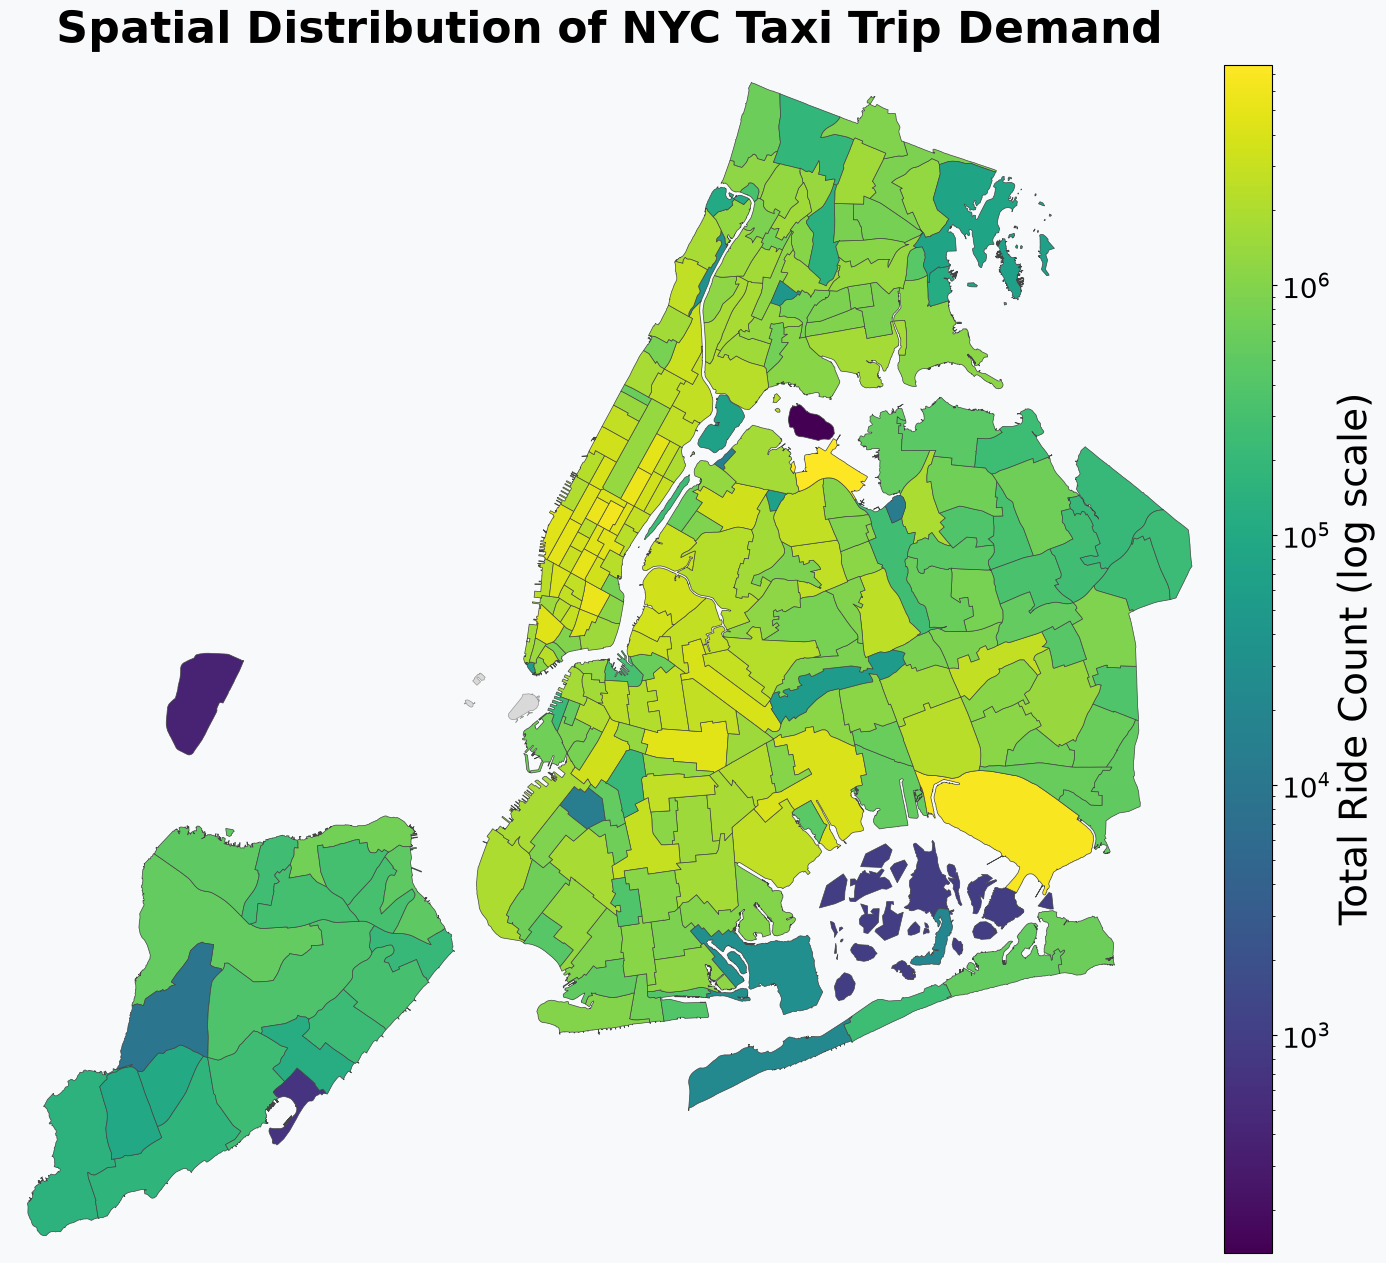

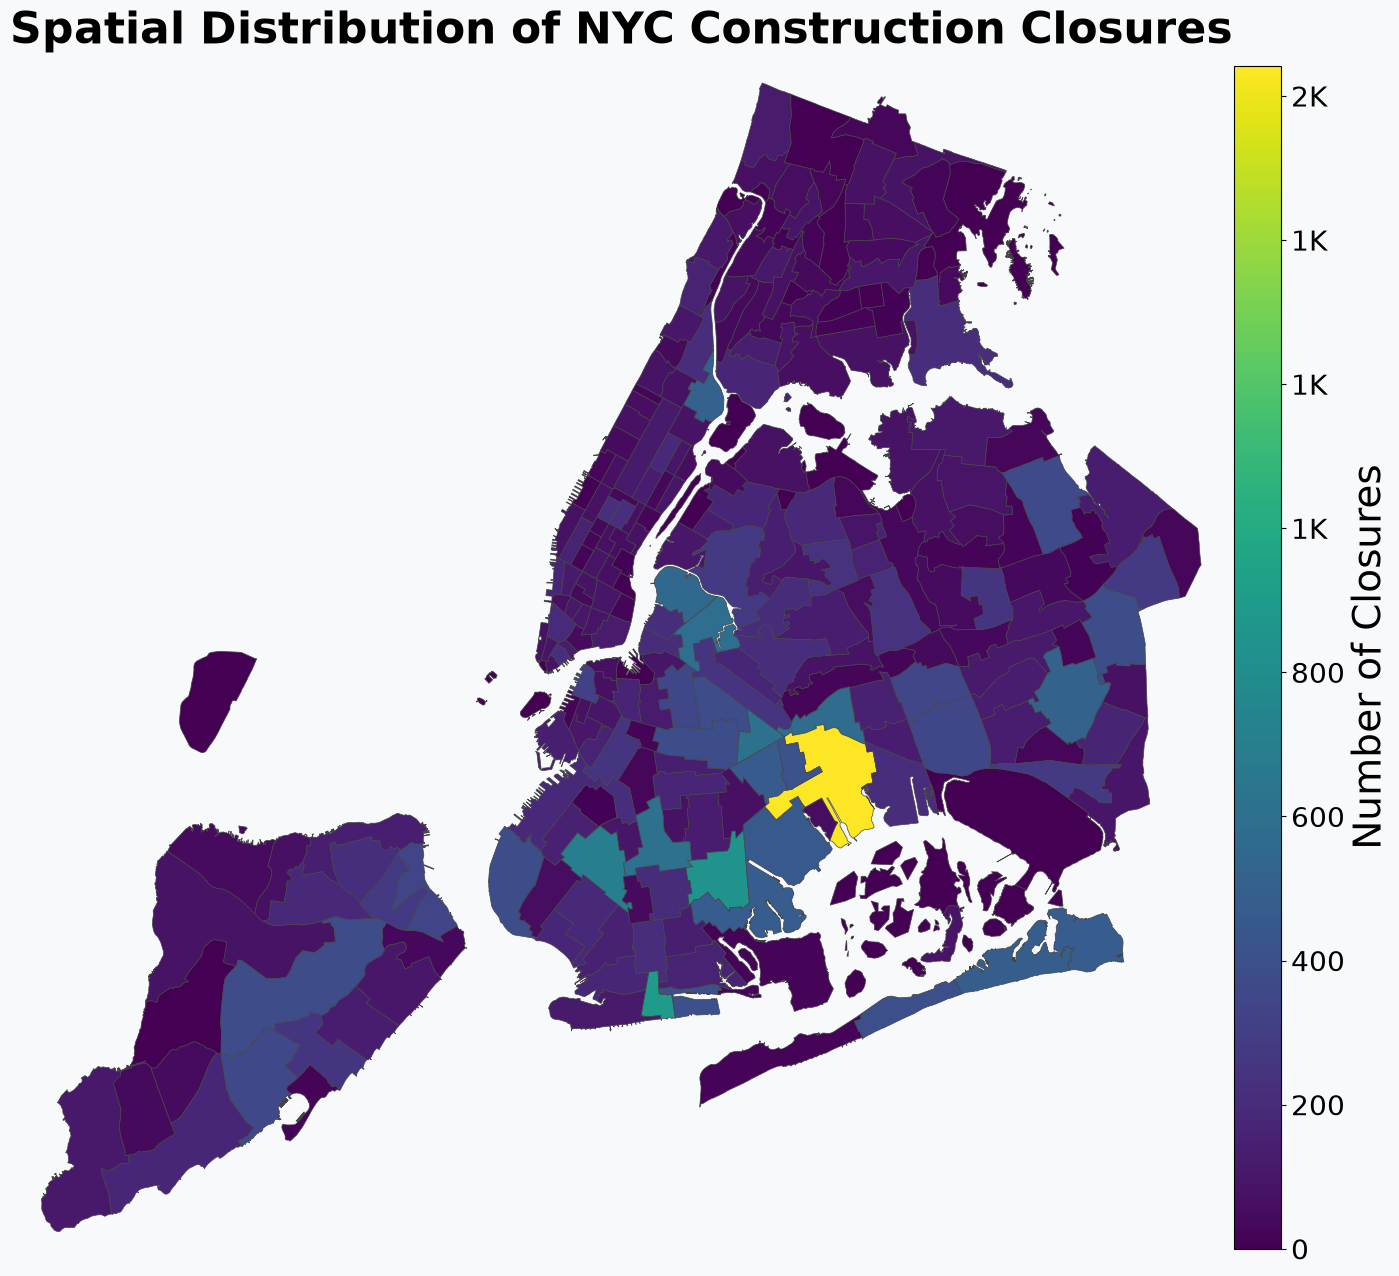

Locations included in closure-bucket comparison: 185


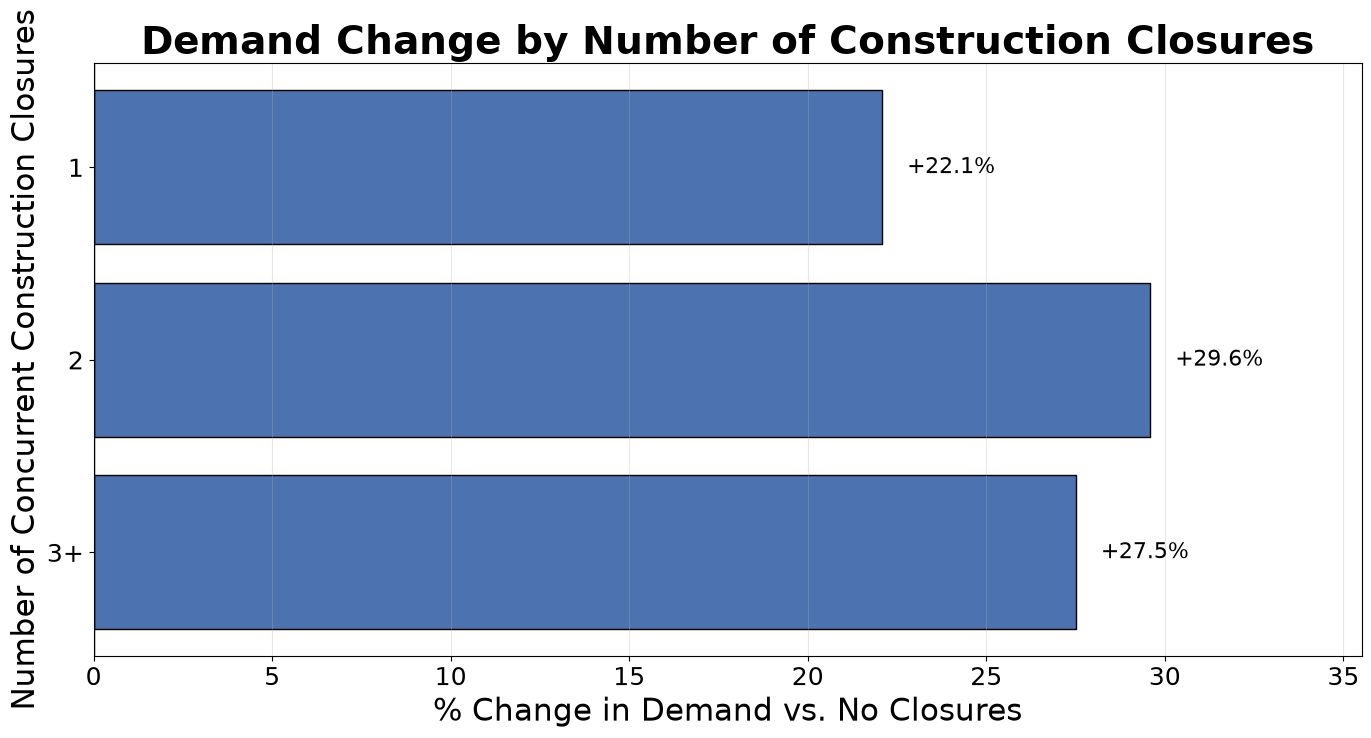

Baseline demand (0 closures): 37.542 rides/location-hr
Avg demand increase per additional closure (after the first): +2.819 rides/location-hr
As % of baseline demand: +7.51% per additional closure


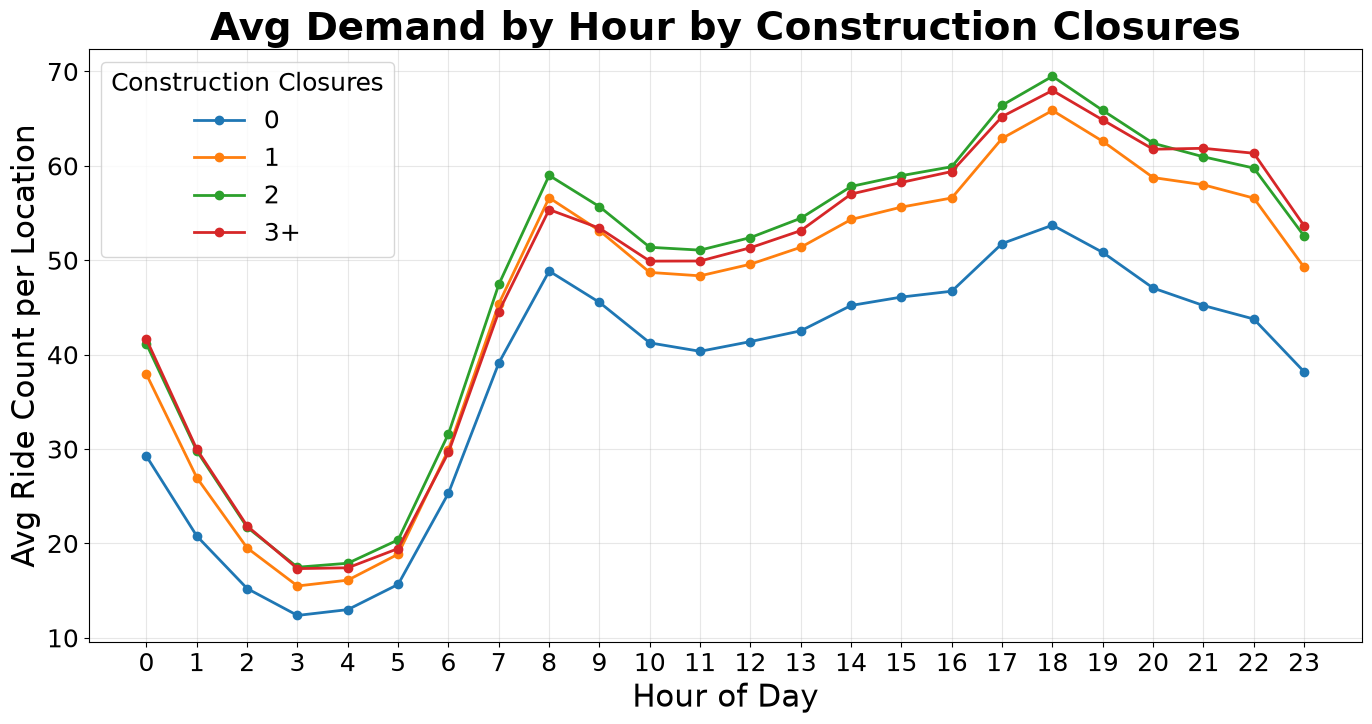

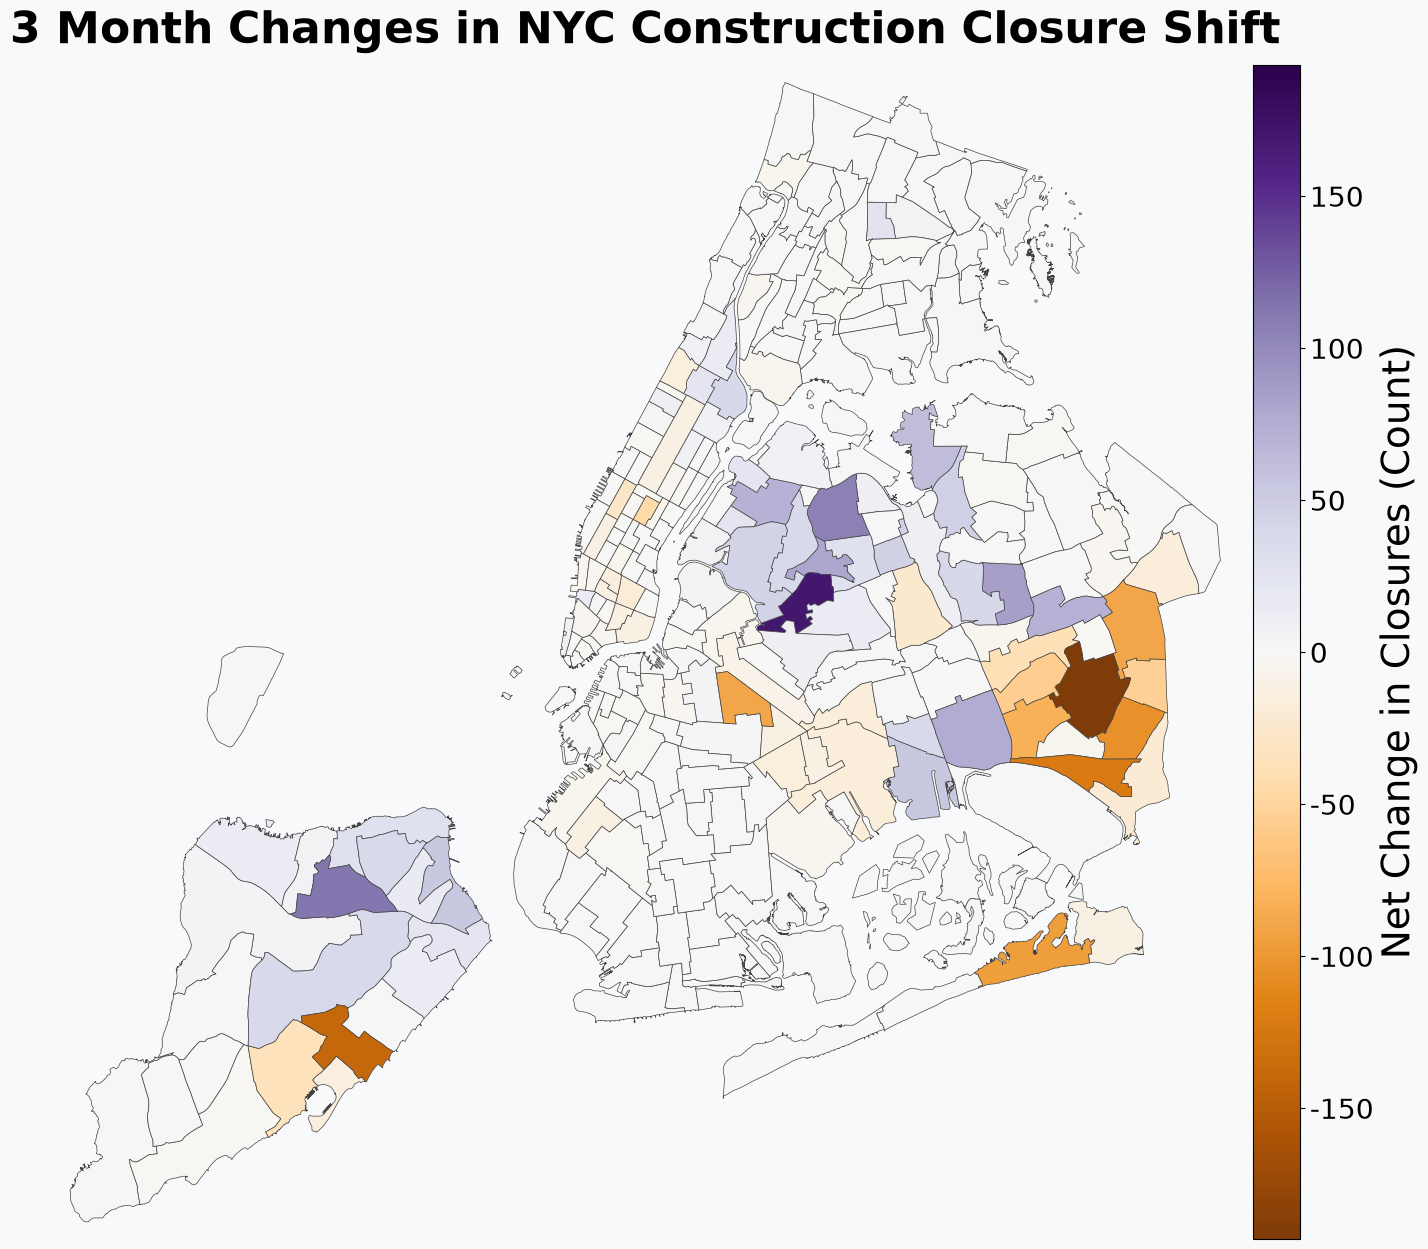


Top 10 locations — closures INCREASED (May → Aug):
 location_id  n_may  n_aug  diff_3mo_total
         157      0    170             170
         251      0    113             113
         129      1    108             107
         121     29    114              85
          83      0     80              80
         216      8     84              76
         131      0     72              72
           7      0     71              71
          53      2     65              63
         221      8     62              54

Top 10 locations — closures DECREASED (May → Aug):
 location_id  n_may  n_aug  diff_3mo_total
         205    193      0            -193
         176    155     15            -140
         219    174     52            -122
         139    105      0            -105
         117    100      4             -96
         225     90      0             -90
         191    107     18             -89
          10     82      0             -82
         215     62      6          

Per-zone demand CHANGE (rides/location-hr) by closure bucket, vs each zone's own 0-closure baseline:
closure_bucket    0      1      2     3+
location_id                             
4               0.0   2.12   2.67   1.96
5               0.0   0.05   0.14  -0.11
6               0.0   0.47   0.13  -0.14
9               0.0   0.41  -0.03   0.32
10              0.0  -0.02  -0.52   0.68
11              0.0  -1.25  -0.86  -0.74
13              0.0  -1.49  -5.31  -1.52
14              0.0  -0.20   2.18   0.27
15              0.0   0.60   0.45   0.22
17              0.0  -4.03 -11.12  -6.87
18              0.0  -3.56  -1.99  -2.53
19              0.0  -0.59  -0.19  -0.10
20              0.0   1.22  -0.30   1.57
21              0.0  -2.05  -1.45  -0.74
22              0.0  -3.38  -5.08  -3.87
23              0.0   0.03   1.32   0.11
24              0.0  -0.57   0.87  -1.00
25              0.0   0.30   0.01   2.58
26              0.0  -0.82   4.18   2.67
27              0.0   0.15   0.03  -0.

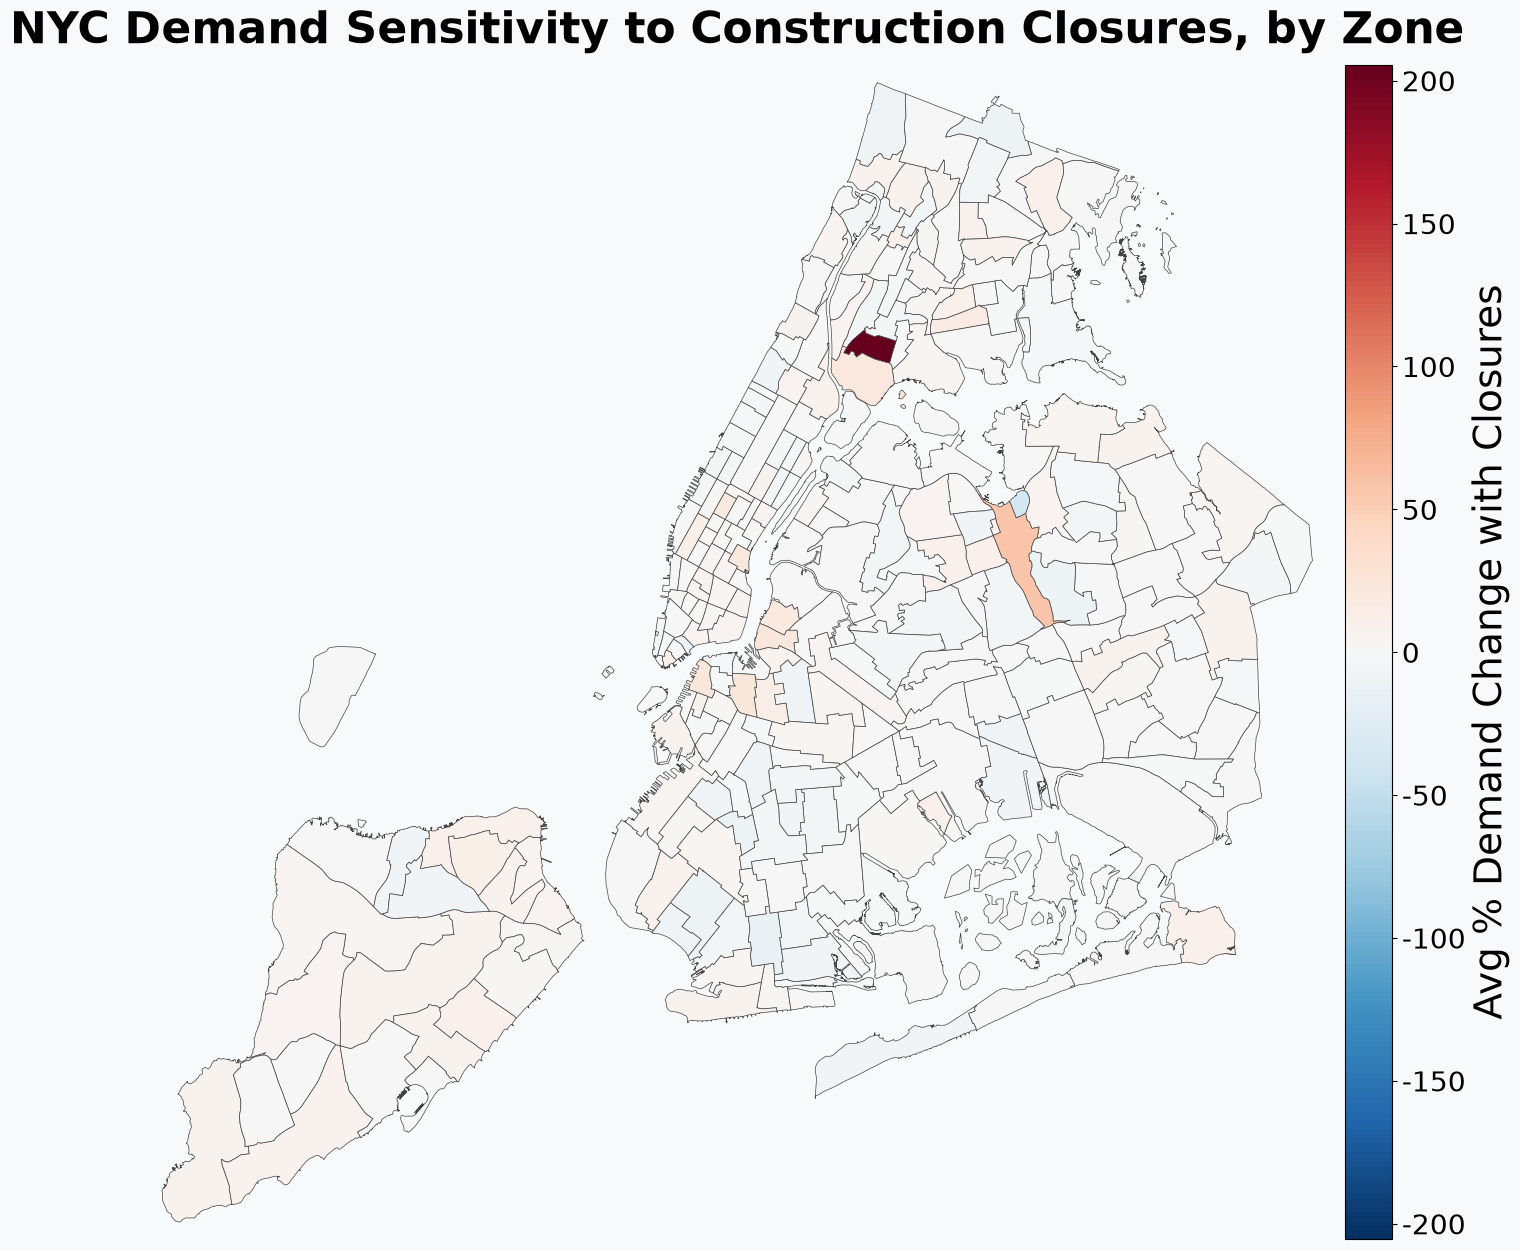


Top 10 zones — demand INCREASES most with closures:
 location_id  avg_amount_change  avg_pct_change
         159              30.12          205.34
          93               3.36           58.53
          33               8.61           23.92
         256              15.60           23.41
          97              12.00           23.15
         168              10.81           21.48
         137              13.61           21.40
         255              15.67           20.58
         230              25.07           19.43
         212               4.27           17.54

Top 10 zones — demand DECREASES most with closures:
 location_id  avg_amount_change  avg_pct_change
         253              -0.28          -36.86
         123              -4.17          -13.47
         209              -2.62          -12.63
          22              -4.11          -11.15
         133              -2.09          -11.09
         135              -1.84          -10.59
         259              -2.8


--- REVENUE IMPACT ESTIMATE ---
Total Incremental Rides (Positive Shift Zones): 8,318 rides
Estimated Gross Revenue Gain from Allocation Shift: $255,139.29


In [1]:
"""NYC Taxi Demand vs Construction Closures — Analysis
1. Map: demand distribution   2. Map: closures distribution
3. Demand % change by concurrent closures (+ marginal effect after the 1st)
4. Avg demand by hour, split by closure bucket
5. Closure shift over the past 3 months
6. Region-level demand change from closures (amount + %)
7. Estimated revenue impact of shifting capacity to positive-shift zones
"""

from datetime import datetime
from functools import reduce

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyspark.sql.functions as F
from matplotlib.ticker import FuncFormatter, LogFormatterSciNotation
from mpl_toolkits.axes_grid1 import make_axes_locatable
from pyspark.sql import SparkSession

# ---------------------------------------------------------------- SETUP ----
spark = (
    SparkSession.builder.appName("MAST30034 Assignment1")
    .config("spark.sql.repl.eagerEval.enabled", True)
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "Etc/UTC")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "2g")
    .getOrCreate()
)

MIN_LOCATION_RIDES = 0   # min rides per (location, bucket) to count in a cohort
MAX_CLOSURE_BUCKET = 3   # counts >= this collapse into "N+"
TODAY = datetime(2026, 8, 31)
# Requiring data in the "N+" bucket too often empties the cohort (rare at high
# concurrency), which is what previously caused the "0" baseline lookup to fail.
REQUIRE_TOP_BUCKET = False

closures = spark.read.csv(
    "../../data/processed/construction_closures.csv", header=True, inferSchema=True
).select(
    F.col("location_id").cast("int"),
    F.to_timestamp("start_time").alias("start_time"),
    F.to_timestamp("end_time").alias("end_time"),
)
pu_agg = spark.read.parquet("../../data/processed/pu_agg.parquet")
zones = gpd.read_file("../../data/taxi_zones/taxi_zones.shp")

# --- shared plot style ---
MAP_FACECOLOR = "#F8F9FA"
plt.rcParams.update({"font.size": 16})
CHART_FIGSIZE = (14, 8)
CHART_TITLE_SIZE, CHART_AXIS_LABEL_SIZE, CHART_TICK_SIZE = 28, 22, 18
CHART_ANNOTATION_SIZE, CHART_LEGEND_SIZE, CHART_LEGEND_TITLE_SIZE = 16, 18, 18
MAP_TARGET_HEIGHT, MAP_DPI = 14, 300
MAP_TITLE_SIZE, MAP_LEGEND_LABEL_SIZE, MAP_LEGEND_TICK_SIZE = 32, 28, 20
SEQ_CMAP, DIV_CMAP = "viridis", "PuOr"  # colorblind-safe sequential / diverging


# ---------------------------------------------------------- MAP HELPERS ----
def human_readable_number(x, _pos):
    """K/M tick labels (avoids matplotlib's clippable scientific offset text)."""
    if abs(x) >= 1_000_000:
        return f"{x / 1_000_000:.1f}M"
    if abs(x) >= 1_000:
        return f"{x / 1_000:.0f}K"
    return f"{x:.0f}"


def get_map_figsize(gdf, target_height=MAP_TARGET_HEIGHT):
    """Match figure aspect to the geometry's bbox so the map fills the frame."""
    minx, miny, maxx, maxy = gdf.total_bounds
    return (round(target_height * (maxx - minx) / (maxy - miny), 2), target_height)


def diverging_norm(series):
    """0-centred TwoSlopeNorm; falls back to +/-1 if every value is 0."""
    max_abs = series.abs().max() or 1
    return mcolors.TwoSlopeNorm(vmin=-max_abs, vcenter=0, vmax=max_abs)


def plot_choropleth(gdf, column, cmap, title, legend_label, norm=None, save_path=None, log_scale=False):
    """Shared report-ready choropleth: bbox-matched aspect, docked colorbar,
    optional log scale (zones with 0/NaN plotted flat since log(0) is undefined)."""
    fig, ax = plt.subplots(figsize=get_map_figsize(gdf), facecolor=MAP_FACECOLOR)
    ax.set_facecolor(MAP_FACECOLOR)
    ax.axis("off")
    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.15)

    if log_scale:
        has_value = gdf[column].notna() & (gdf[column] > 0)
        gdf[~has_value].plot(color="#D9D9D9", edgecolor="#999999", linewidth=0.5, ax=ax)
        gdf[has_value].plot(
            column=column, cmap=cmap, linewidth=0.5, edgecolor="#444444", legend=True, cax=cax, ax=ax,
            norm=mcolors.LogNorm(vmin=gdf.loc[has_value, column].min(), vmax=gdf.loc[has_value, column].max()),
            legend_kwds={"label": f"{legend_label} (log scale)"},
        )
    else:
        gdf.plot(
            column=column, cmap=cmap, norm=norm, linewidth=0.5, edgecolor="#444444", legend=True, cax=cax, ax=ax,
            legend_kwds={"label": legend_label},
            missing_kwds={"color": "#D9D9D9", "edgecolor": "#999999", "label": "No Data"},
        )

    cax.tick_params(labelsize=MAP_LEGEND_TICK_SIZE)
    cax.yaxis.label.set_size(MAP_LEGEND_LABEL_SIZE)
    cax.yaxis.set_major_formatter(
        LogFormatterSciNotation(base=10, labelOnlyBase=False) if log_scale else FuncFormatter(human_readable_number)
    )

    minx, miny, maxx, maxy = gdf.total_bounds
    pad_x, pad_y = (maxx - minx) * 0.015, (maxy - miny) * 0.015
    ax.set_xlim(minx - pad_x, maxx + pad_x)
    ax.set_ylim(miny - pad_y, maxy + pad_y)
    ax.set_title(title, fontsize=MAP_TITLE_SIZE, fontweight="bold", pad=16)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=MAP_DPI, bbox_inches="tight", facecolor=MAP_FACECOLOR)
    plt.show()


# ------------------------------------------------ 1 & 2. DEMAND / CLOSURE MAPS ----
demand_by_location = pu_agg.groupBy("location_id").agg(F.sum("ride_count").alias("total_rides")).toPandas()
demand_map = zones.merge(demand_by_location, left_on="LocationID", right_on="location_id", how="left")
demand_map["total_rides"] = demand_map["total_rides"].fillna(0)
plot_choropleth(demand_map, "total_rides", SEQ_CMAP, "Spatial Distribution of NYC Taxi Trip Demand",
                 "Total Ride Count", log_scale=True)

closures_by_location = closures.groupBy("location_id").agg(F.count("*").alias("n_closures")).toPandas()
closures_map = zones.merge(closures_by_location, left_on="LocationID", right_on="location_id", how="left")
closures_map["n_closures"] = closures_map["n_closures"].fillna(0)
plot_choropleth(closures_map, "n_closures", SEQ_CMAP, "Spatial Distribution of NYC Construction Closures",
                 "Number of Closures")


# ------------------------------------------------------- BUCKETING HELPERS ----
BUCKET_ORDER = [str(i) for i in range(MAX_CLOSURE_BUCKET)] + [f"{MAX_CLOSURE_BUCKET}+"]


def bucket_column(closure_col="construction_count", max_bucket=MAX_CLOSURE_BUCKET):
    return F.when(F.col(closure_col) >= max_bucket, F.lit(f"{max_bucket}+")).otherwise(F.col(closure_col).cast("string"))


def get_common_locations(df, closure_col="construction_count", max_bucket=MAX_CLOSURE_BUCKET,
                          require_top_bucket=REQUIRE_TOP_BUCKET):
    """Locations with >= MIN_LOCATION_RIDES in every *required* closure bucket.
    Top ("N+") bucket is optional by default since it's sparse and, if required,
    can empty the cohort entirely."""
    bucket_totals = (
        df.withColumn("closure_bucket", bucket_column(closure_col, max_bucket))
        .groupBy("location_id", "closure_bucket").agg(F.sum("ride_count").alias("total_rides"))
        .filter(F.col("total_rides") >= MIN_LOCATION_RIDES)
    )
    required = [str(i) for i in range(max_bucket)] + ([f"{max_bucket}+"] if require_top_bucket else [])
    return (
        bucket_totals.filter(F.col("closure_bucket").isin(required))
        .groupBy("location_id").agg(F.countDistinct("closure_bucket").alias("n"))
        .filter(F.col("n") == len(required)).select("location_id")
    )


def pivot_by_bucket(pdf, index_col, value_col):
    return pdf.pivot(index=index_col, columns="closure_bucket", values=value_col).reindex(columns=BUCKET_ORDER)


# ------------------------------------------ 3. DEMAND % CHANGE BY CLOSURES ----
common_locations = get_common_locations(pu_agg)
n_common = common_locations.count()
if n_common == 0:
    raise ValueError(
        "0 common locations across closure buckets — nothing to compare. Try lowering "
        "MIN_LOCATION_RIDES, keep REQUIRE_TOP_BUCKET=False, or inspect: "
        'pu_agg.withColumn("b", bucket_column()).groupBy("b").count().show()'
    )
print(f"Locations included in closure-bucket comparison: {n_common}")

bucketed = pu_agg.join(common_locations, "location_id").withColumn("closure_bucket", bucket_column())

demand_by_count = bucketed.groupBy("closure_bucket").agg(F.avg("ride_count").alias("avg_demand")).toPandas()
demand_by_count["closure_bucket"] = pd.Categorical(demand_by_count["closure_bucket"], BUCKET_ORDER, ordered=True)
demand_by_count = demand_by_count.sort_values("closure_bucket").reset_index(drop=True)

baseline_rows = demand_by_count.loc[demand_by_count["closure_bucket"] == "0", "avg_demand"]
if baseline_rows.empty:
    raise ValueError(
        'No "0-closure" bucket after bucketing/joining — the cohort likely excludes every location '
        'that ever has 0 closures. Check: bucketed.groupBy("closure_bucket").count().show()'
    )
baseline = baseline_rows.iloc[0]
demand_by_count["pct_change_vs_no_closure"] = (demand_by_count["avg_demand"] - baseline) / baseline * 100

# --- chart: % change vs. no-closure baseline (baseline row carries no info -> dropped) ---
plot_data = demand_by_count[demand_by_count["closure_bucket"] != "0"]
fig, ax = plt.subplots(figsize=CHART_FIGSIZE)
colors = ["#4C72B0" if v >= 0 else "#C44E52" for v in plot_data["pct_change_vs_no_closure"]]
bars = ax.barh(plot_data["closure_bucket"].astype(str), plot_data["pct_change_vs_no_closure"], color=colors, edgecolor="black")
ax.invert_yaxis()  # "1" at the top, reading top-to-bottom in closure-count order
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="% Change in Demand vs. No Closures", ylabel="Number of Concurrent Construction Closures")
ax.xaxis.label.set_size(CHART_AXIS_LABEL_SIZE)
ax.yaxis.label.set_size(CHART_AXIS_LABEL_SIZE)
ax.set_title("Demand Change by Number of Construction Closures", fontsize=CHART_TITLE_SIZE, fontweight="bold")
ax.tick_params(labelsize=CHART_TICK_SIZE)
ax.grid(alpha=0.3, axis="x")
ax.margins(x=0.2)
for bar, val in zip(bars, plot_data["pct_change_vs_no_closure"]):
    ax.annotate(f"{val:+.1f}%", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                textcoords="offset points", xytext=(18 if val >= 0 else -18, 0),
                ha="left" if val >= 0 else "right", va="center", fontsize=CHART_ANNOTATION_SIZE)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# --- marginal effect: demand change per additional closure, AFTER the first ---
# Only exact counts 1..MAX_CLOSURE_BUCKET-1 (excludes grouped "N+" and the 0-closure
# baseline: 0->1 is "any closure vs none", a different effect from each closure after).
marginal_data = demand_by_count[demand_by_count["closure_bucket"].astype(str).str.isnumeric()].copy()
marginal_data["closure_count"] = marginal_data["closure_bucket"].astype(str).astype(int)
marginal_data = marginal_data[marginal_data["closure_count"] >= 1]

print(f"Baseline demand (0 closures): {baseline:.3f} rides/location-hr")
if len(marginal_data) >= 2:
    slope, _ = np.polyfit(marginal_data["closure_count"], marginal_data["avg_demand"], 1)
    print(f"Avg demand increase per additional closure (after the first): {slope:+.3f} rides/location-hr")
    print(f"As % of baseline demand: {slope / baseline * 100:+.2f}% per additional closure")
else:
    print(f"Need >= 2 numeric closure-count buckets (>=1 closure) to fit a slope; "
          f"MAX_CLOSURE_BUCKET={MAX_CLOSURE_BUCKET} gives too few. Consider raising it.")

# ---------------------------------------- 4. AVG DEMAND BY HOUR, BY BUCKET ----
hourly = bucketed.groupBy("hour", "closure_bucket").agg(F.avg("ride_count").alias("avg_demand_rides")).toPandas()
pivot = pivot_by_bucket(hourly, "hour", "avg_demand_rides")

fig, ax = plt.subplots(figsize=CHART_FIGSIZE)
pivot.plot(ax=ax, marker="o", linewidth=2)
ax.set(xlabel="Hour of Day", ylabel="Avg Ride Count per Location")
ax.xaxis.label.set_size(CHART_AXIS_LABEL_SIZE)
ax.yaxis.label.set_size(CHART_AXIS_LABEL_SIZE)
ax.set_title("Avg Demand by Hour by Construction Closures", fontsize=CHART_TITLE_SIZE, fontweight="bold")
ax.set_xticks(range(24))
ax.tick_params(labelsize=CHART_TICK_SIZE)
ax.legend(title="Construction Closures", fontsize=CHART_LEGEND_SIZE, title_fontsize=CHART_LEGEND_TITLE_SIZE, loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# ------------------------------------------- 5. CLOSURE SHIFT — PAST 3 MOS ----
def count_active_on(df, snapshot_date, col_name):
    return (
        df.filter((F.col("start_time") <= F.lit(snapshot_date))
                  & (F.col("end_time").isNull() | (F.col("end_time") >= F.lit(snapshot_date))))
        .groupBy("location_id").agg(F.count("*").alias(col_name))
    )


snapshots = {"may": datetime(2026, 5, 31), "jun": datetime(2026, 6, 30), "jul": datetime(2026, 7, 31), "aug": TODAY}
snap_dfs = [count_active_on(closures, dt, f"n_{label}") for label, dt in snapshots.items()]
wide = reduce(lambda a, b: a.join(b, "location_id", "outer"), snap_dfs).fillna(0)
wide = wide.withColumn("diff_3mo_total", F.col("n_aug") - F.col("n_may"))
wide_pd = wide.toPandas()

merged = zones.merge(wide_pd, left_on="LocationID", right_on="location_id", how="left")
merged["diff_3mo_total"] = merged["diff_3mo_total"].fillna(0)
plot_choropleth(merged, "diff_3mo_total", DIV_CMAP, "3 Month Changes in NYC Construction Closure Shift",
                 "Net Change in Closures (Count)", norm=diverging_norm(merged["diff_3mo_total"]))

cols = ["location_id", "n_may", "n_aug", "diff_3mo_total"]
print("\nTop 10 locations — closures INCREASED (May → Aug):")
print(wide_pd.nlargest(10, "diff_3mo_total")[cols].to_string(index=False))
print("\nTop 10 locations — closures DECREASED (May → Aug):")
print(wide_pd.nsmallest(10, "diff_3mo_total")[cols].to_string(index=False))

# --------------------------------- 6. REGION-LEVEL DEMAND CHANGE (AMT + %) ----
per_loc_bucket = bucketed.groupBy("location_id", "closure_bucket").agg(F.avg("ride_count").alias("avg_demand"))
per_loc_baseline = per_loc_bucket.filter(F.col("closure_bucket") == "0").select(
    "location_id", F.col("avg_demand").alias("baseline_demand")
)
region_change = (
    per_loc_bucket.join(per_loc_baseline, "location_id")
    .withColumn("demand_change_amount", F.col("avg_demand") - F.col("baseline_demand"))
    .withColumn("demand_change_pct",
                F.when(F.col("baseline_demand") == 0, F.lit(None))
                .otherwise(F.col("demand_change_amount") / F.col("baseline_demand") * 100))
).toPandas()
region_change["closure_bucket"] = pd.Categorical(region_change["closure_bucket"], BUCKET_ORDER, ordered=True)

print("Per-zone demand CHANGE (rides/location-hr) by closure bucket, vs each zone's own 0-closure baseline:")
print(pivot_by_bucket(region_change, "location_id", "demand_change_amount").round(2).to_string())
print("\nPer-zone demand CHANGE (%) by closure bucket, vs each zone's own 0-closure baseline:")
print(pivot_by_bucket(region_change, "location_id", "demand_change_pct").round(1).to_string())

# --- single summary per zone: avg effect across every non-zero closure bucket ---
overall_effect = (
    region_change[region_change["closure_bucket"] != "0"]
    .groupby("location_id")
    .agg(avg_amount_change=("demand_change_amount", "mean"), avg_pct_change=("demand_change_pct", "mean"))
    .reset_index()
)
effect_map = zones.merge(overall_effect, left_on="LocationID", right_on="location_id", how="left")
effect_map["avg_pct_change"] = effect_map["avg_pct_change"].fillna(0)
plot_choropleth(effect_map, "avg_pct_change", "RdBu_r", "NYC Demand Sensitivity to Construction Closures, by Zone",
                 "Avg % Demand Change with Closures", norm=diverging_norm(effect_map["avg_pct_change"]))

effect_cols = ["location_id", "avg_amount_change", "avg_pct_change"]
print("\nTop 10 zones — demand INCREASES most with closures:")
print(overall_effect.nlargest(10, "avg_pct_change")[effect_cols].round(2).to_string(index=False))
print("\nTop 10 zones — demand DECREASES most with closures:")
print(overall_effect.nsmallest(10, "avg_pct_change")[effect_cols].round(2).to_string(index=False))

# ------------------------------- 7. REVENUE IMPACT OF CAPACITY REALLOCATION ----
# NOTE: `observed_hours` counts *distinct hours-of-day* (0-23), not total hours
# observed over the ~3-month window, so it understates true incremental rides.
# Worth revisiting before citing total_revenue_gain as a real dollar estimate.
zone_revenue = bucketed.groupBy("location_id").agg(
    F.avg("avg_total_amount").alias("mean_zone_fare"), F.countDistinct("hour").alias("observed_hours")
).toPandas()

revenue_impact = overall_effect.merge(zone_revenue, on="location_id")
revenue_impact["positive_hourly_shift"] = revenue_impact["avg_amount_change"].clip(lower=0)
revenue_impact["total_incremental_rides"] = revenue_impact["positive_hourly_shift"] * revenue_impact["observed_hours"]
revenue_impact["total_revenue_gain"] = revenue_impact["total_incremental_rides"] * revenue_impact["mean_zone_fare"]

print("\n--- REVENUE IMPACT ESTIMATE ---")
print(f"Total Incremental Rides (Positive Shift Zones): {revenue_impact['total_incremental_rides'].sum():,.0f} rides")
print(f"Estimated Gross Revenue Gain from Allocation Shift: ${revenue_impact['total_revenue_gain'].sum():,.2f}")

In [ ]:
# ------------- 8. SKEW-MANAGED vs UNMANAGED: AVG DEMAND CHANGE PER CLOSURE ----
# Compares the marginal effect from section 3 (skew-managed) against the same
# measurement with no skew management. Read-only w.r.t. sections 1-7: reuses
# `pu_agg` and `marginal_data` / `baseline` but defines only new names.
#
# Managed (current analysis, section 3):
#   - Closure skew (outer regions): high concurrent-closure counts are rare and
#     concentrated in a few zones, so counts >= MAX_CLOSURE_BUCKET pool into "N+"
#     and the slope is fitted only on the well-populated exact counts (1..N-1).
#   - Ride skew (Manhattan): only `common_locations` (zones observed at every
#     required closure level) are compared, so changes in WHICH zones appear at
#     each closure level can't masquerade as a demand change.
# Unmanaged: raw pu_agg, every zone, every exact closure count, no cohort/pooling.

# --- managed: refit from section 3's marginal_data (doesn't touch `slope`) ---
managed_slope, managed_intercept = np.polyfit(marginal_data["closure_count"], marginal_data["avg_demand"], 1)
managed_pct = managed_slope / baseline * 100

# --- unmanaged: pooled avg demand at every exact closure count, all zones ---
raw_by_count = (
    pu_agg.groupBy("construction_count")
    .agg(F.avg("ride_count").alias("avg_demand"), F.count("*").alias("n_obs"),
         F.countDistinct("location_id").alias("n_zones"))
    .toPandas().sort_values("construction_count").reset_index(drop=True)
)
raw_baseline = raw_by_count.loc[raw_by_count["construction_count"] == 0, "avg_demand"].iloc[0]
raw_marginal = raw_by_count[raw_by_count["construction_count"] >= 1]
raw_slope, raw_intercept = np.polyfit(raw_marginal["construction_count"], raw_marginal["avg_demand"], 1)
raw_pct = raw_slope / raw_baseline * 100

skew_comparison = pd.DataFrame({
    "method": ["Skew-managed (current)", "No skew management"],
    "zones": [n_common, int(pu_agg.select("location_id").distinct().count())],
    "closure_counts_fitted": [f"{marginal_data['closure_count'].min()}-{marginal_data['closure_count'].max()}",
                              f"{raw_marginal['construction_count'].min()}-{raw_marginal['construction_count'].max()}"],
    "baseline_rides_per_loc_hr": [baseline, raw_baseline],
    "change_per_closure_rides": [managed_slope, raw_slope],
    "change_per_closure_pct": [managed_pct, raw_pct],
})
print("Avg demand change per additional closure (after the first):")
print(skew_comparison.round(3).to_string(index=False))
print(f"\nDifference (managed - unmanaged): {managed_slope - raw_slope:+.3f} rides/location-hr, "
      f"{managed_pct - raw_pct:+.2f} pp of baseline")

# --- chart: left = demand curves + fitted trends, right = % per closure ---
MANAGED_COLOR, RAW_COLOR = "#4C72B0", "#C44E52"
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw={"width_ratios": [1.6, 1]})

ax_l.scatter(raw_marginal["construction_count"], raw_marginal["avg_demand"], color=RAW_COLOR, alpha=0.55,
             s=np.clip(raw_marginal["n_obs"] / raw_marginal["n_obs"].max() * 400, 15, 400),
             label="No skew management (point size = # obs)")
x_raw = np.array([raw_marginal["construction_count"].min(), raw_marginal["construction_count"].max()])
ax_l.plot(x_raw, raw_intercept + raw_slope * x_raw, color=RAW_COLOR, linewidth=2.5, linestyle="--",
          label=f"Unmanaged trend ({raw_slope:+.2f}/closure)")
ax_l.scatter(marginal_data["closure_count"], marginal_data["avg_demand"], color=MANAGED_COLOR, s=160,
             edgecolor="black", zorder=3, label="Skew-managed (current)")
x_man = np.array([marginal_data["closure_count"].min(), marginal_data["closure_count"].max()])
ax_l.plot(x_man, managed_intercept + managed_slope * x_man, color=MANAGED_COLOR, linewidth=3, zorder=3,
          label=f"Managed trend ({managed_slope:+.2f}/closure)")
ax_l.axhline(baseline, color=MANAGED_COLOR, linewidth=1, linestyle=":")
ax_l.axhline(raw_baseline, color=RAW_COLOR, linewidth=1, linestyle=":")
ax_l.set(xlabel="Number of Concurrent Construction Closures", ylabel="Avg Ride Count per Location-Hour")
ax_l.set_title("Demand vs Closures", fontsize=CHART_TITLE_SIZE - 4, fontweight="bold")
ax_l.legend(fontsize=CHART_LEGEND_SIZE - 4, loc="best")

bars = ax_r.barh(skew_comparison["method"], skew_comparison["change_per_closure_pct"],
                 color=[MANAGED_COLOR if v >= 0 else RAW_COLOR for v in skew_comparison["change_per_closure_pct"]],
                 edgecolor="black")
ax_r.invert_yaxis()
ax_r.axvline(0, color="black", linewidth=1)
ax_r.set(xlabel="% Demand Change per Additional Closure")
ax_r.set_title("Marginal Effect per Closure", fontsize=CHART_TITLE_SIZE - 4, fontweight="bold")
ax_r.margins(x=0.35)
for bar, val in zip(bars, skew_comparison["change_per_closure_pct"]):
    ax_r.annotate(f"{val:+.2f}%", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                  textcoords="offset points", xytext=(12 if val >= 0 else -12, 0),
                  ha="left" if val >= 0 else "right", va="center", fontsize=CHART_ANNOTATION_SIZE)

for ax in (ax_l, ax_r):
    ax.xaxis.label.set_size(CHART_AXIS_LABEL_SIZE)
    ax.yaxis.label.set_size(CHART_AXIS_LABEL_SIZE)
    ax.tick_params(labelsize=CHART_TICK_SIZE)
    ax.grid(alpha=0.3)
fig.suptitle("Effect of Skew Management on Demand Change per Closure", fontsize=CHART_TITLE_SIZE, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()